In [182]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.preprocessing import LabelEncoder
import seaborn as sns
import seaborn.objects as so


In [11]:
df  = pd.read_excel("C:\\Users\\Adroit\\Desktop\\ASSIGNMENTS\\PROGRAMMING FOR MASSIVE DATA\\Clustering project\\Cleaned_Mall_Customers.xlsx")
df.head(20)

,CustomerID,Gender,Age,Education,Marital Status,Annual Income (k$),Spending Score (1-100)
0,1,M,19,High School,Married,15,39
1,2,M,21,Graduate,Single,15,81
2,3,F,20,Graduate,Married,16,6
3,4,F,23,High School,Unknown,16,77
4,5,F,31,Uneducated,Married,17,40
5,6,F,22,Graduate,Married,17,76
6,7,F,35,Unknown,Married,18,6
7,8,F,23,High School,Unknown,18,94
8,9,M,64,Uneducated,Single,19,3
9,10,F,30,Graduate,Single,19,72


In [ ]:
le = LabelEncoder()
df['Gender_encoded'] = le.fit_transform(df['Gender']) # 1 = Male, 0 = Female
df ['Education_encoded'] = le.fit_transform(df['Education'])# 0  = college, 1 = Doctorate, 2 = graduate, 3 = High School, 4 = Post Graduate, 5 = Uneducated, 6 = Unknown 
df ['Marital_Status_encoded'] = le.fit_transform(df['Marital Status']) # 1 = Married, 2 = Single, 3 = Unknown, 4 = Divorced
df.drop(['Gender', 'Education', 'Marital Status'], axis=1, inplace=True)

In [35]:
scaler = StandardScaler()
df[['Age_T','Annual Income (k$)_T','Gender_encoded_T','Education_encoded_T','Marital_Status_encoded_T','Spending_Score_T']] = scaler.fit_transform(df[['Age','Annual Income (k$)','Gender_encoded','Education_encoded','Marital_Status_encoded','Spending Score (1-100)']])
print(df.head(20))

    CustomerID  Age  Annual Income (k$)  Spending Score (1-100)  \
0            1   19                  15                      39   
1            2   21                  15                      81   
2            3   20                  16                       6   
3            4   23                  16                      77   
4            5   31                  17                      40   
5            6   22                  17                      76   
6            7   35                  18                       6   
7            8   23                  18                      94   
8            9   64                  19                       3   
9           10   30                  19                      72   
10          11   67                  19                      14   
11          12   35                  19                      99   
12          13   58                  20                      15   
13          14   24                  20                      7

In [54]:
selected = df[['Age_T','Annual Income (k$)_T','Spending_Score_T','Education_encoded_T']]

In [36]:
def optimize_k_means(data, max_k):
    means = []
    inertias = []
    for k in range (1, max_k):
        kmeans = KMeans (n_clusters = k)
        kmeans.fit(data)
        means.append(k)
        inertias.append(kmeans.inertia_)
    
    fig = plt.subplots(figsize=(10, 5))
    plt.plot(means, inertias, 'o-')
    plt.xlabel('Number of Clusters')
    plt.ylabel('Inertia')
    plt.grid (True)
    plt.show()

c:\Users\Adroit\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Adroit\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Adroit\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Adroit\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Wi

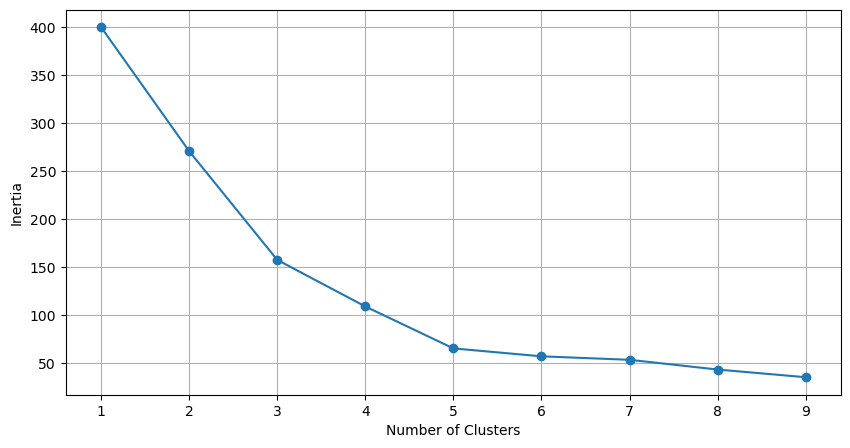

In [91]:
optimize_k_means(df[['Annual Income (k$)_T','Spending_Score_T']], 10)

In [186]:
kmeans = KMeans(n_clusters=5, random_state=1)


In [187]:
kmeans.fit(df[['Annual Income (k$)_T','Spending_Score_T']])

c:\Users\Adroit\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


KMeans(n_clusters=5, random_state=1)

In [188]:
centroids = kmeans.cluster_centers_

In [113]:
df['kmeans_5'] = kmeans.labels_

In [97]:
df

,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Gender_encoded,Education_encoded,Marital_Status_encoded,Age_T,Annual Income (k$)_T,Gender_encoded_T,Education_encoded_T,Marital_Status_encoded_T,Spending_Score_T,kmeans_5,kmeans_4,Income_level
0,1,19,15,39,1,3,1,-1.424569,-1.738999,1.128152,-0.022543,-0.553667,-0.434801,0,0,Low income
1,2,21,15,81,1,2,2,-1.281035,-1.738999,1.128152,-0.586122,0.848022,1.195704,0,1,Low income
2,3,20,16,6,0,2,1,-1.352802,-1.700830,-0.886405,-0.586122,-0.553667,-1.715913,4,0,High income
3,4,23,16,77,0,3,3,-1.137502,-1.700830,-0.886405,-0.022543,2.249711,1.040418,0,1,Low income
4,5,31,17,40,0,5,1,-0.563369,-1.662660,-0.886405,1.104615,-0.553667,-0.395980,0,0,Low income
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,196,35,120,79,0,3,1,-0.276302,2.268791,-0.886405,-0.022543,-0.553667,1.118061,3,2,Upper-Middle income
196,197,45,126,28,0,3,3,0.441365,2.497807,-0.886405,-0.022543,2.249711,-0.861839,2,3,Middle income
197,198,32,126,74,1,5,1,-0.491602,2.497807,1.128152,1.104615,-0.553667,0.923953,3,2,Upper-Middle income
198,199,32,137,18,1,3,1,-0.491602,2.917671,1.128152,-0.022543,-0.553667,-1.250054,2,3,Middle income


In [143]:
df['clusters'] = [label_dict.get(i) for i in df['kmeans_5']]
df.head(10)

,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Gender_encoded,Education_encoded,Marital_Status_encoded,Age_T,Annual Income (k$)_T,Gender_encoded_T,Education_encoded_T,Marital_Status_encoded_T,Spending_Score_T,kmeans_5,kmeans_4,Income_level,clusters,kmeans_3
0,1,19,15,39,1,3,1,-1.424569,-1.738999,1.128152,-0.022543,-0.553667,-0.434801,4,0,Low income,High income-High spend,4
1,2,21,15,81,1,2,2,-1.281035,-1.738999,1.128152,-0.586122,0.848022,1.195704,1,1,Low income,Low income-High spend,1
2,3,20,16,6,0,2,1,-1.352802,-1.700830,-0.886405,-0.586122,-0.553667,-1.715913,4,0,High income,High income-High spend,4
3,4,23,16,77,0,3,3,-1.137502,-1.700830,-0.886405,-0.022543,2.249711,1.040418,1,1,Low income,Low income-High spend,1
4,5,31,17,40,0,5,1,-0.563369,-1.662660,-0.886405,1.104615,-0.553667,-0.395980,4,0,Low income,High income-High spend,4
5,6,22,17,76,0,2,1,-1.209269,-1.662660,-0.886405,-0.586122,-0.553667,1.001596,1,1,Low income,Low income-High spend,1
6,7,35,18,6,0,6,1,-0.276302,-1.624491,-0.886405,1.668195,-0.553667,-1.715913,4,0,High income,High income-High spend,4
7,8,23,18,94,0,3,3,-1.137502,-1.624491,-0.886405,-0.022543,2.249711,1.700384,1,1,Low income,Low income-High spend,1
8,9,64,19,3,1,5,2,1.804932,-1.586321,1.128152,1.104615,0.848022,-1.832378,4,0,Lower-Middle income,High income-High spend,4
9,10,30,19,72,0,2,2,-0.635135,-1.586321,-0.886405,-0.586122,0.848022,0.846310,1,1,Low income,Low income-High spend,1


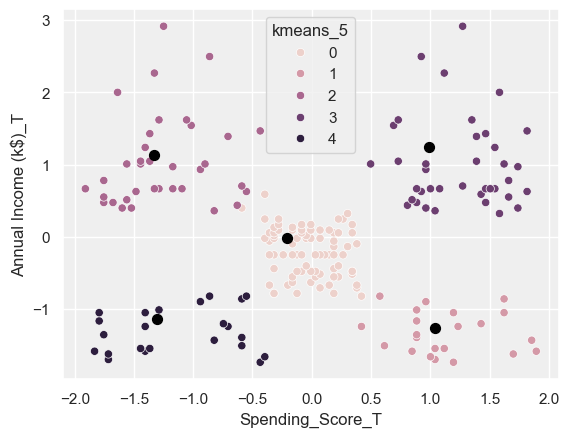

In [190]:

ax = sns.scatterplot(
    data=df,
    y='Annual Income (k$)_T',
    x='Spending_Score_T',
    hue='kmeans_5',


   
)
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    s=200,
    c='black',
    marker='.',
    label='Centroids'
)
plt.show()

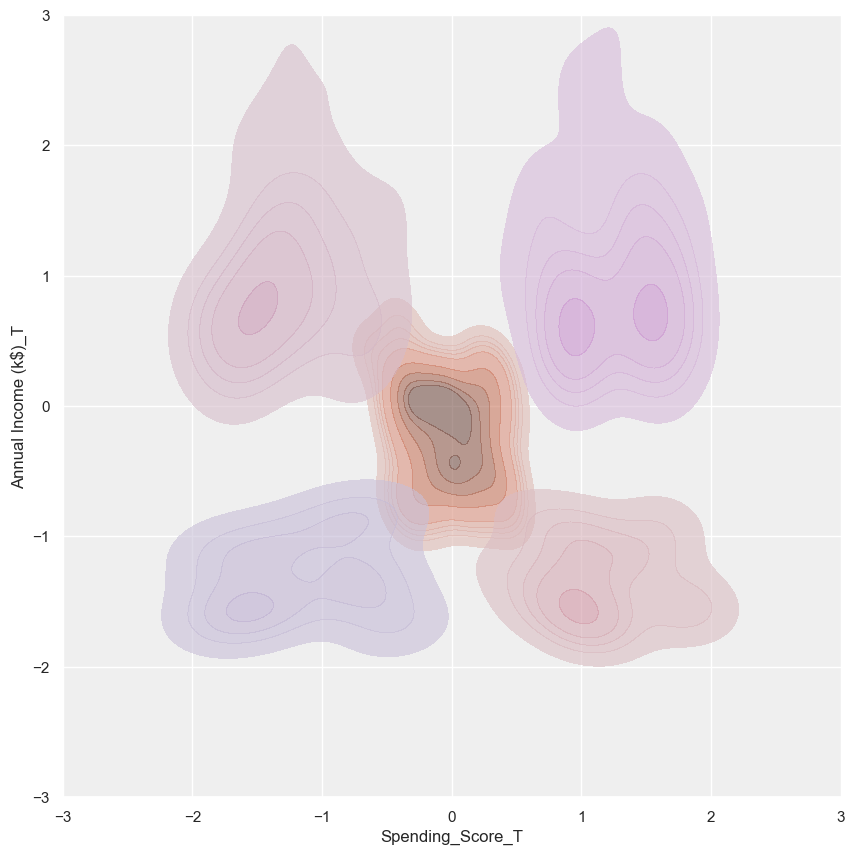

In [155]:
sns.set(rc={'axes.facecolor':'EFEFEF'})
ax = sns.jointplot(x=df['Spending_Score_T'], y=df['Annual Income (k$)_T'],
              cut = 2, hue=df['kmeans_5'],
        
              xlim=[-3,3], ylim=[-3,3],
              kind='kde', fill=True,
              height=10, ratio=6,
              joint_kws = dict(alpha=0.6),
              marginal_kws=dict(fill=True),
              legend=False)
ax.ax_marg_x.remove()
ax.ax_marg_y.remove()
plt.show()

In [160]:
df['kmeans_5'].value_counts()

kmeans_5
0    80
3    39
2    36
4    23
1    22
Name: count, dtype: int64

In [167]:
df.drop (['Age_T','Gender_encoded_T','Education_encoded_T','Marital_Status_encoded_T','kmeans_4','kmeans_3','clusters','CustomerID'], axis=1, inplace=True)
df

KeyError: "['Age_T', 'Gender_encoded_T', 'Education_encoded_T', 'Marital_Status_encoded_T', 'kmeans_4', 'kmeans_3', 'clusters', 'CustomerID'] not found in axis"

In [171]:
df['kmeans_5'] = df['kmeans_5'].astype('int64')

In [181]:
df.groupby('kmeans_5').median(numeric_only=True)

,Age,Annual Income (k$),Spending Score (1-100),Gender_encoded,Education_encoded,Marital_Status_encoded,Annual Income (k$)_T,Spending_Score_T
kmeans_5,,,,,,,,
0,46.5,54.0,50.0,0.0,2.0,1.0,-0.250391,-0.007764
1,23.5,24.5,77.0,0.0,3.0,1.0,-1.376390,1.040418
2,41.5,83.0,16.0,1.0,3.0,1.0,0.856522,-1.327697
3,32.0,79.0,83.0,0.0,3.0,1.0,0.703844,1.273347
4,46.0,25.0,17.0,0.0,3.0,1.0,-1.357305,-1.288876


In [ ]:
#Interpretation
# 0 = mid income, moderate spending
# 1 = low income, high spending
# 2 = high income, low spending
# 3 = high income, high spending
# 4 = low income, low spending
# younger people are likely to be low income high spenders
# men are likely to be high income low spenders
# majority of people are mid income moderate spenders
# the smallest group are the low income high spenders
# most mid income moderate spenders are educated to the graduate level

